<center>
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/IDSNlogo.png" width="300" alt="cognitiveclass.ai logo">
</center>

# Pie Charts, Box Plots, Scatter Plots, and Bubble Plots

Estimated time needed: **30** minutes

## Objectives

After completing this lab you will be able to:

*   Explore Matplotlib library further
*   Create pie charts, box plots, scatter plots and bubble charts


## Table of Contents

<div class="alert alert-block alert-info" style="margin-top: 20px">

1.  [Exploring Datasets with *p*andas](#0)<br>
2.  [Downloading and Prepping Data](#2)<br>
3.  [Visualizing Data using Matplotlib](#4) <br>
4.  [Pie Charts](#6) <br>
5.  [Box Plots](#8) <br>
6.  [Scatter Plots](#10) <br>
7.  [Bubble Plots](#12) <br>

</div>


# Importing Libraries<a id="0"></a>


In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline
plt.style.use('ggplot')
plt.rcParams.update({'figure.figsize': (8, 4.2), 'figure.dpi': 100,
                     'font.size': 10, 'figure.autolayout': True})
pd.set_option('display.max_columns', 10)
pd.set_option('display.max_rows', 12)
print('pandas:', pd.__version__, '| Matplotlib:', mpl.__version__)

pandas: 2.2.3 | Matplotlib: 3.9.2


## Importing Data <a id="2"></a>
Dataset: Immigration to Canada from 1980 to 2013 - [International migration flows to and from selected countries - The 2015 revision](https://www.un.org/development/desa/pd/data/international-migration-flows) from United Nation's website.<br>
In this lab, we will focus on the Canadian Immigration data and use the *already cleaned dataset* and can be fetched from <a href="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.csv">here</a>.
<br><br>
You can refer to the lab on data pre-processing wherein this dataset is cleaned for a quick refresh your Panads skill [Data pre-processing with Pandas](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/june2023_updates/Module%201/DV0101EN-Exercise-Dataset-Preprocessing-Exploring-with-Pandas.ipynb)


In [2]:
df_can = pd.read_csv('../data/Canada.csv')
print('Canada.csv loaded:', df_can.shape)

Canada.csv loaded: (195, 39)


In [3]:
df_can.head()

,Country,Continent,Region,DevName,1980,...,2010,2011,2012,2013,Total
0,Afghanistan,Asia,Southern Asia,Developing regions,16,...,1758,2203,2635,2004,58639
1,Albania,Europe,Southern Europe,Developed regions,1,...,561,539,620,603,15699
2,Algeria,Africa,Northern Africa,Developing regions,80,...,4752,4325,3774,4331,69439
3,American Samoa,Oceania,Polynesia,Developing regions,0,...,0,0,0,0,6
4,Andorra,Europe,Southern Europe,Developed regions,0,...,0,0,1,1,15


Let's find out how many entries there are in our dataset.


In [4]:
# print the dimensions of the dataframe
print(df_can.shape)

(195, 39)


# Visualizing Data using Matplotlib<a id="4"></a>


For plotting the data easilty, let's first set the country name as index - useful for quickly looking up countries using .loc method.


In [5]:
df_can.set_index('Country', inplace=True)

In [6]:
# Let's view the first five elements and see how the dataframe was changed
df_can.head()

,Continent,Region,DevName,1980,1981,...,2010,2011,2012,2013,Total
Country,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,...,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,...,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,...,4752,4325,3774,4331,69439
American Samoa,Oceania,Polynesia,Developing regions,0,1,...,0,0,0,0,6
Andorra,Europe,Southern Europe,Developed regions,0,0,...,0,0,1,1,15


Notice now the country names now serve as indices.


In [7]:
print('data dimensions:', df_can.shape)

data dimensions: (195, 38)


Finally, let's create a list of years from 1980 - 2013, this will come in handy when we start plotting the data


In [8]:
years = list(map(str, range(1980, 2014)))

# Pie Charts <a id="6"></a>

A `pie chart` is a circular graphic that displays numeric proportions by dividing a circle (or pie) into proportional slices. You are most likely already familiar with pie charts as it is widely used in business and media. We can create pie charts in Matplotlib by passing in the `kind=pie` keyword.

Let's use a pie chart to explore the proportion (percentage) of new immigrants grouped by continents for the entire time period from 1980 to 2013.


Step 1: Gather data.

We will use *pandas* `groupby` method to summarize the immigration data by `Continent`. The general process of `groupby` involves the following steps:

1.  **Split:** Splitting the data into groups based on some criteria.
2.  **Apply:** Applying a function to each group independently:
    .sum()
    .count()
    .mean()
    .std()
    .aggregate()
    .apply()
    .etc..
3.  **Combine:** Combining the results into a data structure.


<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/Mod3Fig4SplitApplyCombine.png" height="400" align="center">


In [9]:
df_continents = df_can.groupby('Continent')[years + ['Total']].sum()
display(df_continents[['Total']])

,Total
Continent,
Africa,618948
Asia,3317794
Europe,1410947
Latin America and the Caribbean,765148
Northern America,241142
Oceania,55174


Step 2: Plot the data. We will pass in `kind = 'pie'` keyword, along with the following additional parameters:

*   `autopct` -  is a string or function used to label the wedges with their numeric value. The label will be placed inside the wedge. If it is a format string, the label will be `fmt%pct`.
*   `startangle` - rotates the start of the pie chart by angle degrees counterclockwise from the x-axis.
*   `shadow` - Draws a shadow beneath the pie (to give a 3D feel).


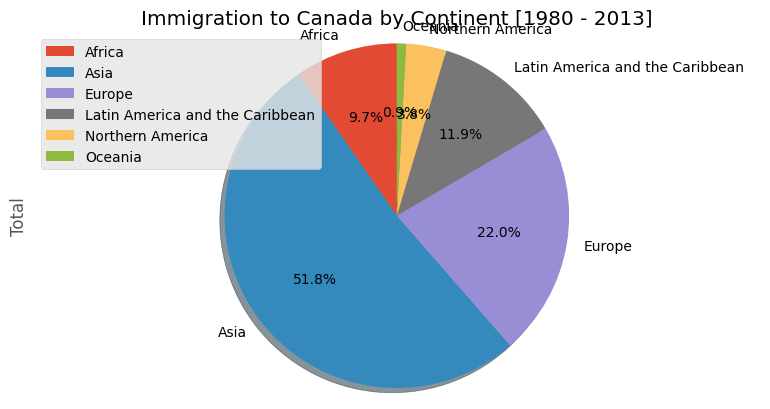

In [10]:
# autopct create %, start angle represent starting point
df_continents['Total'].plot(kind='pie',
                            figsize=(8, 4.2),
                            autopct='%1.1f%%', # add in percentages
                            startangle=90,     # start angle 90° (Africa)
                            shadow=True,       # add shadow      
                            )

plt.title('Immigration to Canada by Continent [1980 - 2013]')
plt.axis('equal') # Sets the pie chart to look like a circle.
plt.legend(labels=df_continents.index, loc='upper left') 


plt.show()

The above visual is not very clear, the numbers and text overlap in some instances. Let's make a few modifications to improve the visuals:

*   Remove the text labels on the pie chart by passing in `legend` and add it as a seperate legend using `plt.legend()`.
*   Push out the percentages to sit just outside the pie chart by passing in `pctdistance` parameter.
*   Pass in a custom set of colors for continents by passing in `colors` parameter.
*   **Explode** the pie chart to emphasize the lowest three continents (Africa, North America, and Latin America and Caribbean) by passing in `explode` parameter.


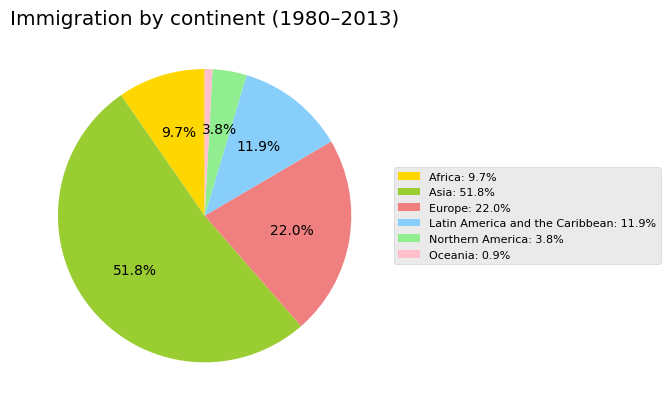

In [11]:
values = df_continents['Total']
shares = values / values.sum() * 100
ax = values.plot(kind='pie', labels=None, startangle=90,
    autopct=lambda p: f'{p:.1f}%' if p >= 2 else '',
    colors=['gold', 'yellowgreen', 'lightcoral', 'lightskyblue', 'lightgreen', 'pink'])
ax.set(title='Immigration by continent (1980–2013)', ylabel='')
ax.legend([f'{c}: {p:.1f}%' for c, p in shares.items()],
    loc='center left', bbox_to_anchor=(1, 0.5), fontsize=8)
plt.show()

**Question:** Using a pie chart, explore the proportion (percentage) of new immigrants grouped by continents in the year 2013.

**Note**: You might need to play with the explore values in order to fix any overlapping slice values.


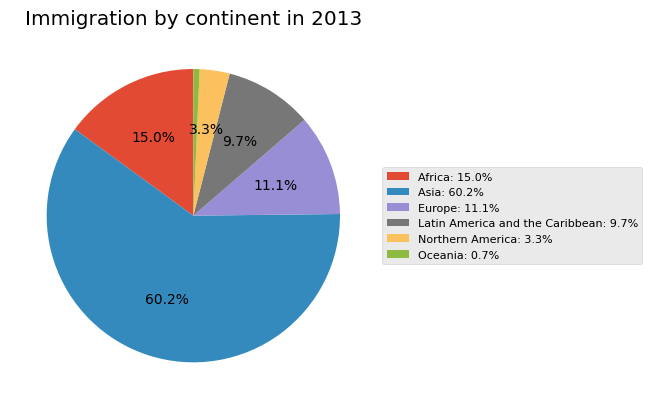

In [12]:
values = df_continents['2013']
shares = values / values.sum() * 100
ax = values.plot(kind='pie', labels=None, startangle=90,
    autopct=lambda p: f'{p:.1f}%' if p >= 2 else '')
ax.set(title='Immigration by continent in 2013', ylabel='')
ax.legend([f'{c}: {p:.1f}%' for c, p in shares.items()],
    loc='center left', bbox_to_anchor=(1, 0.5), fontsize=8)
plt.show()

<details><summary>Click here for a sample python solution</summary>

```python
# The correct answer is:

explode_list = [0.0, 0, 0, 0.1, 0.1, 0.2]  # ratio for each continent with which to offset each wedge

df_continents['2013'].plot(
    kind='pie',
    figsize=(15, 6),
    autopct='%1.1f%%',
    startangle=90,
    shadow=True,
    labels=None,              # turn off labels on pie chart
    pctdistance=1.12,         # the ratio between the pie center and start of text label
    explode=explode_list      # 'explode' lowest 3 continents
)

# scale the title up by 12% to match pctdistance
plt.title('Immigration to Canada by Continent in 2013', y=1.12)
plt.axis('equal')

# add legend
plt.legend(labels=df_continents.index, loc='upper left')

# show plot
plt.show()


```

</details>


# Box Plots <a id="8"></a>

A `box plot` is a way of statistically representing the *distribution* of the data through five main dimensions:

*   **Minimum:** The smallest number in the dataset excluding the outliers.
*   **First quartile:** Middle number between the `minimum` and the `median`.
*   **Second quartile (Median):** Middle number of the (sorted) dataset.
*   **Third quartile:** Middle number between `median` and `maximum`.
*   **Maximum:** The largest number in the dataset excluding the outliers.


<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/boxplot_complete.png" width="440," align="center">


To make a `boxplot`, we can use `kind=box` in `plot` method invoked on a *pandas* series or dataframe.

Let's plot the box plot for the Japanese immigrants between 1980 - 2013.


Step 1: Get the subset of the dataset. Even though we are extracting the data for just one country, we will obtain it as a dataframe. This will help us with calling the `dataframe.describe()` method to view the percentiles.


In [13]:
# to get a dataframe, place extra square brackets around 'Japan'.
df_japan = df_can.loc[['Japan'], years].transpose()
df_japan.head()

Country,Japan
1980,701
1981,756
1982,598
1983,309
1984,246


Step 2: Plot by passing in `kind='box'`.


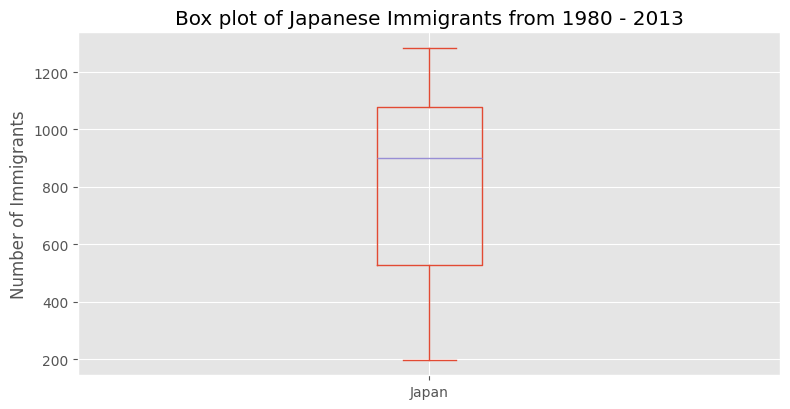

In [14]:
df_japan.plot(kind='box', figsize=(8, 4.2))

plt.title('Box plot of Japanese Immigrants from 1980 - 2013')
plt.ylabel('Number of Immigrants')

plt.show()

We can immediately make a few key observations from the plot above:

1.  The minimum number of immigrants is around 200 (min), maximum number is around 1300 (max), and  median number of immigrants is around 900 (median).
2.  25% of the years for period 1980 - 2013 had an annual immigrant count of \~500 or fewer (First quartile).
3.  75% of the years for period 1980 - 2013 had an annual immigrant count of \~1100 or fewer (Third quartile).

We can view the actual numbers by calling the `describe()` method on the dataframe.


In [15]:
df_japan.describe()

Country,Japan
count,34.000000
mean,814.911765
std,337.219771
min,198.000000
25%,529.000000
50%,902.000000
75%,1079.000000
max,1284.000000


One of the key benefits of box plots is comparing the distribution of multiple datasets. In one of the previous labs, we observed that China and India had very similar immigration trends. Let's analyze these two countries further using box plots.

**Question:** Compare the distribution of the number of new immigrants from India and China for the period 1980 - 2013.


Step 1: Get the dataset for China and India and call the dataframe **df_CI**.


In [16]:
df_CI = df_can.loc[['China', 'India'], years].T
df_CI.index = df_CI.index.astype(int)
display(df_CI.head())

Country,China,India
1980,5123,8880
1981,6682,8670
1982,3308,8147
1983,1863,7338
1984,1527,5704


<details><summary>Click here for a sample python solution</summary>

```python
#The correct answer is:
df_CI= df_can.loc[['China', 'India'], years].transpose()
df_CI.head()
```

</details>


Let's view the percentiles associated with both countries using the `describe()` method.


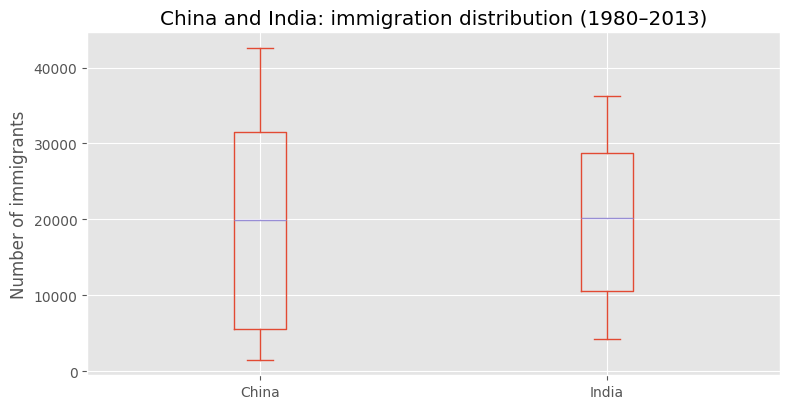

In [17]:
df_CI.plot(kind='box')
plt.title('China and India: immigration distribution (1980–2013)')
plt.ylabel('Number of immigrants')
plt.show()

<details><summary>Click here for a sample python solution</summary>

```python
#The correct answer is:
df_CI.describe()
```

</details>


Step 2: Plot data.


In [18]:
display(df_CI.describe().round(2))

Country,China,India
count,34.00,34.00
mean,19410.65,20350.12
std,13568.23,10007.34
min,1527.00,4211.00
25%,5512.75,10637.75
50%,19945.00,20235.00
75%,31568.50,28699.50
max,42584.00,36210.00


<details><summary>Click here for a sample python solution</summary>

```python
#The correct answer is:
df_CI.plot(kind='box', figsize=(10, 7))

plt.title('Box plots of Immigrants from China and India (1980 - 2013)')
plt.ylabel('Number of Immigrants')

plt.show()

```

</details>


We can observe that, while both countries have around the same median immigrant population (\~20,000),  China's immigrant population range is more spread out than India's. The maximum population from India for any year (36,210) is around 15% lower than the maximum population from China (42,584).


If you prefer to create horizontal box plots, you can pass the `vert` parameter in the **plot** function and assign it to *False*. You can also specify a different color in case you are not a big fan of the default red color.


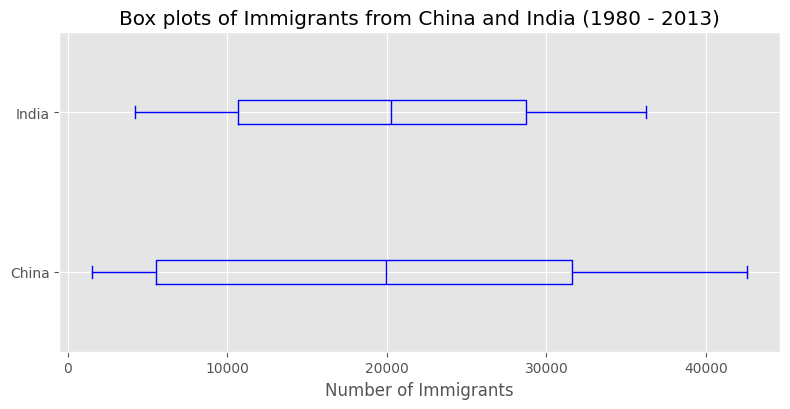

In [19]:
# horizontal box plots
df_CI.plot(kind='box', figsize=(8, 4.2), color='blue', vert=False)

plt.title('Box plots of Immigrants from China and India (1980 - 2013)')
plt.xlabel('Number of Immigrants')

plt.show()

**Subplots**

Often times we might want to plot multiple plots within the same figure. For example, we might want to perform a side by side comparison of the box plot with the line plot of China and India's immigration.

To visualize multiple plots together, we can create a **`figure`** (overall canvas) and divide it into **`subplots`**, each containing a plot. With **subplots**, we usually work with the **artist layer** instead of the **scripting layer**.

Typical syntax is : <br>

```python
    fig = plt.figure() # create figure
    ax = fig.add_subplot(nrows, ncols, plot_number) # create subplots
```

Where

*   `nrows` and `ncols` are used to notionally split the figure into (`nrows` \* `ncols`) sub-axes,
*   `plot_number` is used to identify the particular subplot that this function is to create within the notional grid. `plot_number` starts at 1, increments across rows first and has a maximum of `nrows` \* `ncols` as shown below.

<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/Mod3Fig5Subplots_V2.png" width="500" align="center">


We can then specify which subplot to place each plot by passing in the `ax` paramemter in `plot()` method as follows:


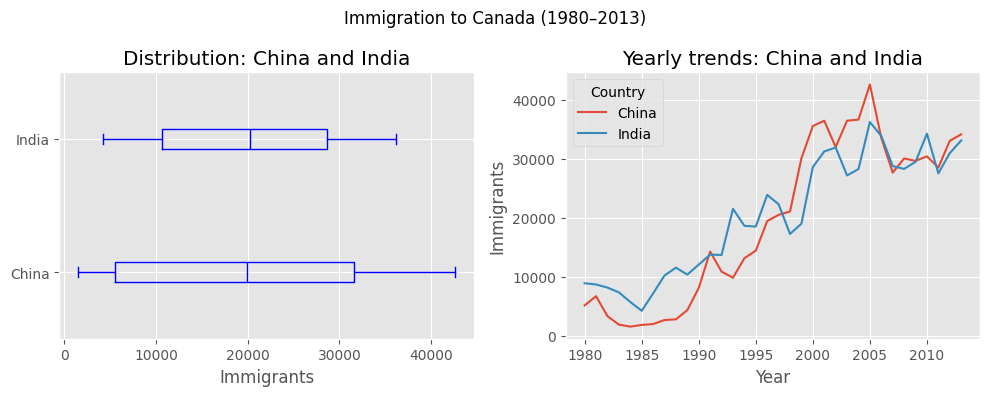

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df_CI.plot(kind='box', vert=False, color='blue', ax=axes[0])
axes[0].set(title='Distribution: China and India', xlabel='Immigrants')
df_CI.plot(kind='line', ax=axes[1])
axes[1].set(title='Yearly trends: China and India',
            xlabel='Year', ylabel='Immigrants')
fig.suptitle('Immigration to Canada (1980–2013)')
fig.tight_layout(); plt.show()

**Tip regarding subplot convention**

In the case when `nrows`, `ncols`, and `plot_number` are all less than 10, a convenience exists such that a 3-digit number can be given instead, where the hundreds represent `nrows`, the tens represent `ncols` and the units represent `plot_number`. For instance,

```python
   subplot(211) == subplot(2, 1, 1) 
```

produces a subaxes in a figure which represents the top plot (i.e. the first) in a 2 rows by 1 column notional grid (no grid actually exists, but conceptually this is how the returned subplot has been positioned).


Let's try something a little more advanced.

Previously we identified the top 15 countries based on total immigration from 1980 - 2013.

**Question:** Create a box plot to visualize the distribution of the top 15 countries (based on total immigration) grouped by the *decades* `1980s`, `1990s`, and `2000s`.


Step 1: Get the dataset. Get the top 15 countries based on Total immigrant population. Name the dataframe **df_top15**.


In [21]:
df_top15 = df_can.nlargest(15, 'Total')
with pd.option_context('display.max_rows', 20):
    display(df_top15[['Total']])

,Total
Country,
India,691904
China,659962
United Kingdom of Great Britain and Northern Ireland,551500
Philippines,511391
Pakistan,241600
United States of America,241122
Iran (Islamic Republic of),175923
Sri Lanka,148358
Republic of Korea,142581


<details><summary>Click here for a sample python solution</summary>

```python
#The correct answer is:
df_top15 = df_can.sort_values(['Total'], ascending=False, axis=0).head(15)
df_top15

```

</details>


Step 2: Create a new dataframe which contains the aggregate for each decade. One way to do that:

1.  Create a list of all years in decades 80's, 90's, and 00's.
2.  Slice the original dataframe df_can to create a series for each decade and sum across all years for each country.
3.  Merge the three series into a new data frame. Call your dataframe **new_df**.


In [22]:
new_df = pd.DataFrame({
    f'{start}s': df_top15[list(map(str, range(start, start + 10)))].sum(axis=1)
    for start in (1980, 1990, 2000)
})
display(new_df.head())

,1980s,1990s,2000s
Country,,,
India,82154,180395,303591
China,32003,161528,340385
United Kingdom of Great Britain and Northern Ireland,179171,261966,83413
Philippines,60764,138482,172904
Pakistan,10591,65302,127598


<details><summary>Click here for a sample python solution</summary>

```python
#The correct answer is:
    
# create a list of all years in decades 80's, 90's, and 00's
years_80s = list(map(str, range(1980, 1990))) 
years_90s = list(map(str, range(1990, 2000))) 
years_00s = list(map(str, range(2000, 2010))) 

# slice the original dataframe df_can to create a series for each decade
df_80s = df_top15.loc[:, years_80s].sum(axis=1) 
df_90s = df_top15.loc[:, years_90s].sum(axis=1) 
df_00s = df_top15.loc[:, years_00s].sum(axis=1)

# merge the three series into a new data frame
new_df = pd.DataFrame({'1980s': df_80s, '1990s': df_90s, '2000s':df_00s}) 

# display dataframe
new_df.head()


```

</details>


Let's learn more about the statistics associated with the dataframe using the `describe()` method.


In [23]:
display(new_df.describe().round(2))

,1980s,1990s,2000s
count,15.00,15.00,15.00
mean,44418.33,85594.67,97471.53
std,44190.68,68237.56,100583.20
min,7613.00,30028.00,13629.00
25%,16698.00,39259.00,36101.50
50%,30638.00,56915.00,65794.00
75%,59183.00,104451.50,105505.50
max,179171.00,261966.00,340385.00


<details><summary>Click here for a sample python solution</summary>

```python
#The correct answer is:    
new_df.describe()
```

</details>


Step 3: Plot the box plots.


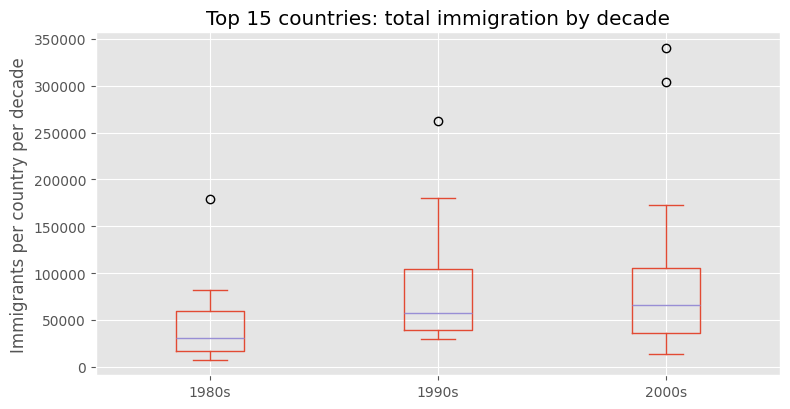

In [24]:
new_df.plot(kind='box')
plt.title('Top 15 countries: total immigration by decade')
plt.ylabel('Immigrants per country per decade')
plt.show()

<details><summary>Click here for a sample python solution</summary>

```python
#The correct answer is:    
new_df.plot(kind='box', figsize=(10, 6))

plt.title('Immigration from top 15 countries for decades 80s, 90s and 2000s')

plt.show()

```

</details>


Note how the box plot differs from the summary table created. The box plot scans the data and identifies the outliers. In order to be an outlier, the data value must be:<br>

*   larger than Q3 by at least 1.5 times the interquartile range (IQR), or,
*   smaller than Q1 by at least 1.5 times the IQR.

Let's look at decade 2000s as an example: <br>

*   Q1 (25%) = 36,101.5 <br>
*   Q3 (75%) = 105,505.5 <br>
*   IQR = Q3 - Q1 = 69,404 <br>

Using the definition of outlier, any value that is greater than Q3 by 1.5 times IQR will be flagged as outlier.

Outlier > 105,505.5 + (1.5 \* 69,404) <br>
Outlier > 209,611.5


In [25]:
q1, q3 = new_df['2000s'].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
outliers = new_df.loc[new_df['2000s'] > upper_fence, ['2000s']]
print('Upper outlier threshold:', upper_fence)
display(outliers)
print('Number of upper outliers:', len(outliers))

Upper outlier threshold: 209611.5


,2000s
Country,
India,303591
China,340385


Number of upper outliers: 2


<details><summary>Click here for a sample python solution</summary>

```python
#The correct answer is:    
new_df=new_df.reset_index()
new_df[new_df['2000s']> 209611.5]

```

</details>


<!-- The correct answer is:
new_df[new_df['2000s']> 209611.5]
-->


China and India are both considered as outliers since their population for the decade exceeds 209,611.5.

The box plot is an advanced visualizaiton tool, and there are many options and customizations that exceed the scope of this lab. Please refer to [Matplotlib documentation](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.boxplot.html) on box plots for more information.


# Scatter Plots <a id="10"></a>

A `scatter plot` (2D) is a useful method of comparing variables against each other. `Scatter` plots look similar to `line plots` in that they both map independent and dependent variables on a 2D graph. While the data points are connected together by a line in a line plot, they are not connected in a scatter plot. The data in a scatter plot is considered to express a trend. With further analysis using tools like regression, we can mathematically calculate this relationship and use it to predict trends outside the dataset.

Let's start by exploring the following:

Using a `scatter plot`, let's visualize the trend of total immigrantion to Canada (all countries combined) for the years 1980 - 2013.


Step 1: Get the dataset. Since we are expecting to use the relationship betewen `years` and `total population`, we will convert `years` to `int` type.


In [26]:
# we can use the sum() method to get the total population per year
df_tot = pd.DataFrame(df_can[years].sum(axis=0))

# change the years to type int (useful for regression later on)
df_tot.index = map(int, df_tot.index)

# reset the index to put in back in as a column in the df_tot dataframe
df_tot.reset_index(inplace = True)

# rename columns
df_tot.columns = ['year', 'total']

# view the final dataframe
df_tot.head()

,year,total
0,1980,99137
1,1981,110563
2,1982,104271
3,1983,75550
4,1984,73417


Step 2: Plot the data. In `Matplotlib`, we can create a `scatter` plot set by passing in `kind='scatter'` as plot argument. We will also need to pass in `x` and `y` keywords to specify the columns that go on the x- and the y-axis.


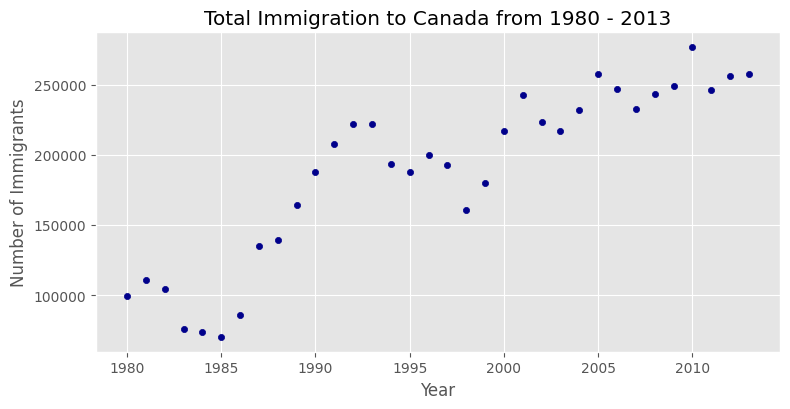

In [27]:
df_tot.plot(kind='scatter', x='year', y='total', figsize=(8, 4.2), color='darkblue')

plt.title('Total Immigration to Canada from 1980 - 2013')
plt.xlabel('Year')
plt.ylabel('Number of Immigrants')

plt.show()

Notice how the scatter plot does not connect the data  points together. We can clearly observe an upward trend in the data: as the years go by, the total number of immigrants increases. We can mathematically analyze this upward trend using a regression line (line of best fit).


So let's try to plot a linear line of best fit, and use it to  predict the number of immigrants in 2015.

Step 1: Get the equation of line of best fit. We will use **Numpy**'s `polyfit()` method by passing in the following:

*   `x`: x-coordinates of the data.
*   `y`: y-coordinates of the data.
*   `deg`: Degree of fitting polynomial. 1 = linear, 2 = quadratic, and so on.


In [28]:
x = df_tot['year']      # year on x-axis
y = df_tot['total']     # total on y-axis
fit = np.polyfit(x, y, deg=1)

fit

array([ 5.56709228e+03, -1.09261952e+07])

The output is an array with the polynomial coefficients, highest powers first. Since we are plotting a linear regression `y= a * x + b`, our output has 2 elements `[5.56709228e+03, -1.09261952e+07]` with the the slope in position 0 and intercept in position 1.

Step 2: Plot the regression line on the `scatter plot`.


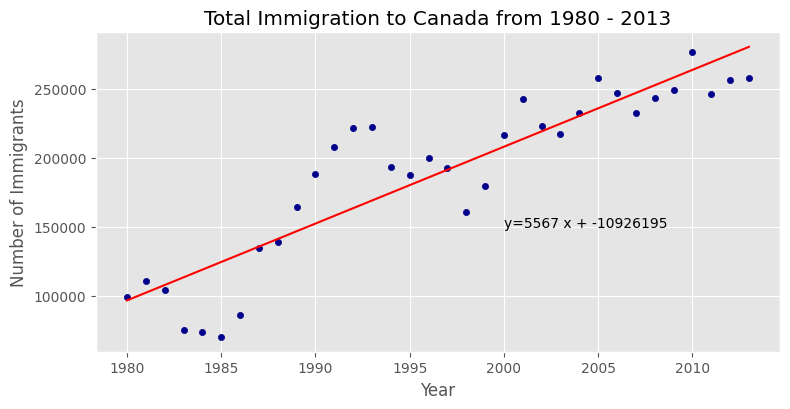

'No. Immigrants = 5567 * Year + -10926195'

In [29]:
df_tot.plot(kind='scatter', x='year', y='total', figsize=(8, 4.2), color='darkblue')

plt.title('Total Immigration to Canada from 1980 - 2013')
plt.xlabel('Year')
plt.ylabel('Number of Immigrants')

# plot line of best fit
plt.plot(x, fit[0] * x + fit[1], color='red') # recall that x is the Years
plt.annotate('y={0:.0f} x + {1:.0f}'.format(fit[0], fit[1]), xy=(2000, 150000))

plt.show()

# print out the line of best fit
'No. Immigrants = {0:.0f} * Year + {1:.0f}'.format(fit[0], fit[1]) 

Using the equation of line of best fit, we can estimate the number of immigrants in 2015:

```python
No. Immigrants = 5567 * Year - 10926195
No. Immigrants = 5567 * 2015 - 10926195
No. Immigrants = 291,310
```

When compared to the actual from Citizenship and Immigration Canada's (CIC) [2016 Annual Report](http://www.cic.gc.ca/english/resources/publications/annual-report-2016/index.asp?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01), we see that Canada accepted 271,845 immigrants in 2015. Our estimated value of 291,310 is within 7% of the actual number, which is pretty good considering our original data came from United Nations (and might differ slightly from CIC data).

As a side note, we can observe that immigration took a dip around 1993 - 1997. Further analysis into the topic revealed that in 1993 Canada introcuded Bill C-86 which introduced revisions to the refugee determination system, mostly restrictive. Further amendments to the Immigration Regulations cancelled the sponsorship required for "assisted relatives" and reduced the points awarded to them, making it more difficult for family members (other than nuclear family) to immigrate to Canada. These restrictive measures had a direct impact on the immigration numbers for the next several years.


**Question**: Create a scatter plot of the total immigration from Denmark, Norway, and Sweden to Canada from 1980 to 2013?


**Step 1**: Get the data:

1.  Create a dataframe the consists of the numbers associated with Denmark, Norway, and Sweden only. Name it **df_countries**.
2.  Sum the immigration numbers across all three countries for each year and turn the result into a dataframe. Name this new dataframe **df_total**.
3.  Reset the index in place.
4.  Rename the columns to **year** and **total**.
5.  Display the resulting dataframe.


In [30]:
dns = df_can.loc[['Denmark', 'Norway', 'Sweden'], years].sum().rename('total')
df_dns = dns.rename_axis('year').reset_index()
df_dns['year'] = df_dns['year'].astype(int)
display(df_dns.head())

,year,total
0,1980,669
1,1981,678
2,1982,627
3,1983,333
4,1984,252


<details><summary>Click here for a sample python solution</summary>

```python
#The correct answer is:  
    
# create df_countries dataframe
df_countries = df_can.loc[['Denmark', 'Norway', 'Sweden'], years].transpose()

# create df_total by summing across three countries for each year
df_total = pd.DataFrame(df_countries.sum(axis=1))

# reset index in place
df_total.reset_index(inplace=True)

# rename columns
df_total.columns = ['year', 'total']

# change column year from string to int to create scatter plot
df_total['year'] = df_total['year'].astype(int)

# show resulting dataframe
df_total.head()


```

</details>


**Step 2**: Generate the scatter plot by plotting the total versus year in **df_total**.


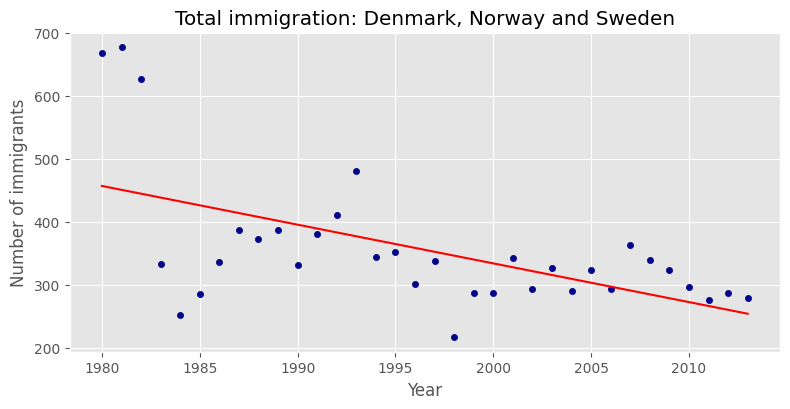

Linear fit: immigrants = -6.15 × year + 12628.16


In [31]:
ax = df_dns.plot(kind='scatter', x='year', y='total', color='darkblue')
slope, intercept = np.polyfit(df_dns['year'], df_dns['total'], 1)
ax.plot(df_dns['year'], slope * df_dns['year'] + intercept, color='red')
ax.set(title='Total immigration: Denmark, Norway and Sweden',
       xlabel='Year', ylabel='Number of immigrants')
plt.show()
print(f'Linear fit: immigrants = {slope:.2f} × year + {intercept:.2f}')

<details><summary>Click here for a sample python solution</summary>

```python
#The correct answer is:  
    
# generate scatter plot
df_total.plot(kind='scatter', x='year', y='total', figsize=(10, 6), color='darkblue')

# add title and label to axes
plt.title('Immigration from Denmark, Norway, and Sweden to Canada from 1980 - 2013')
plt.xlabel('Year')
plt.ylabel('Number of Immigrants')

# show plot
plt.show()


```

</details>


# Bubble Plots <a id="12"></a>

A `bubble plot` is a variation of the `scatter plot` that displays three dimensions of data (x, y, z). The data points are replaced with bubbles, and the size of the bubble is determined by the third variable `z`, also known as the weight. In `maplotlib`, we can pass in an array or scalar to the parameter `s` to `plot()`, that contains the weight of each point.

**Let's start by analyzing the effect of Argentina's great depression**.

Argentina suffered a great depression from 1998 to 2002, which caused widespread unemployment, riots, the fall of the government, and a default on the country's foreign debt. In terms of income, over 50% of Argentines were poor, and seven out of ten Argentine children were poor at the depth of the crisis in 2002.

Let's analyze the effect of this crisis, and compare Argentina's immigration to that of it's neighbour Brazil. Let's do that using a `bubble plot` of immigration from Brazil and Argentina for the years 1980 - 2013. We will set the weights for the bubble as the *normalized* value of the population for each year.


**Step 1**: Get the data for Brazil and Argentina. Like in the previous example, we will convert the `Years` to type int and include it in the dataframe.


In [32]:
# transposed dataframe
df_can_t = df_can[years].transpose()

# cast the Years (the index) to type int
df_can_t.index = map(int, df_can_t.index)

# let's label the index. This will automatically be the column name when we reset the index
df_can_t.index.name = 'Year'

# reset index to bring the Year in as a column
df_can_t.reset_index(inplace=True)

# view the changes
df_can_t.head()

Country,Year,Afghanistan,Albania,Algeria,American Samoa,...,Viet Nam,Western Sahara,Yemen,Zambia,Zimbabwe
0,1980,16,1,80,0,...,1191,0,1,11,72
1,1981,39,0,67,1,...,1829,0,2,17,114
2,1982,39,0,71,0,...,2162,0,1,11,102
3,1983,47,0,69,0,...,3404,0,6,7,44
4,1984,71,0,63,0,...,7583,0,0,16,32


**Step 2**: Create the normalized weights.

There are several methods of normalizations in statistics, each with its own use. In this case, we will use [feature scaling](https://en.wikipedia.org/wiki/Feature_scaling?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01) to bring all values into the range \[0, 1]. The general formula is:

<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/Mod3Fig3FeatureScaling.png" align="center">

where $X$ is the original value, $X'$ is the corresponding normalized value. The formula sets the max value in the dataset to 1, and sets the min value to 0. The rest of the data points are scaled to a value between 0-1 accordingly.


In [33]:
# normalize Brazil data
norm_brazil = (df_can_t['Brazil'] - df_can_t['Brazil'].min()) / (df_can_t['Brazil'].max() - df_can_t['Brazil'].min())

# normalize Argentina data
norm_argentina = (df_can_t['Argentina'] - df_can_t['Argentina'].min()) / (df_can_t['Argentina'].max() - df_can_t['Argentina'].min())

**Step 3**: Plot the data.

*   To plot two different scatter plots in one plot, we can include the axes one plot into the other by passing it via the `ax` parameter.
*   We will also pass in the weights using the `s` parameter. Given that the normalized weights are between 0-1, they won't be visible on the plot. Therefore, we will:
    *   multiply weights by 2000 to scale it up on the graph, and,
    *   add 10 to compensate for the min value (which has a 0 weight and therefore scale with $\times 2000$).


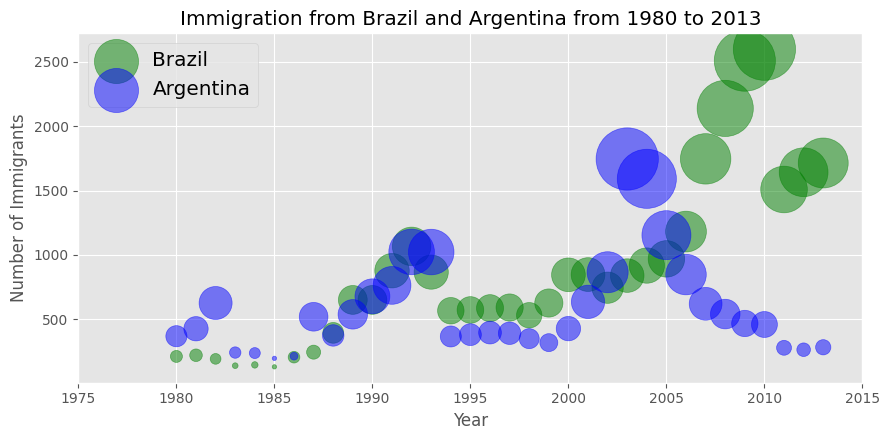

In [34]:
# Brazil
ax0 = df_can_t.plot(kind='scatter',
                    x='Year',
                    y='Brazil',
                    figsize=(9, 4.5),
                    alpha=0.5,  # transparency
                    color='green',
                    s=norm_brazil * 2000 + 10,  # pass in weights 
                    xlim=(1975, 2015)
                    )

# Argentina
ax1 = df_can_t.plot(kind='scatter',
                    x='Year',
                    y='Argentina',
                    alpha=0.5,
                    color="blue",
                    s=norm_argentina * 2000 + 10,
                    ax=ax0
                    )

ax0.set_ylabel('Number of Immigrants')
ax0.set_title('Immigration from Brazil and Argentina from 1980 to 2013')
ax0.legend(['Brazil', 'Argentina'], loc='upper left', fontsize='x-large')

The size of the bubble corresponds to the magnitude of immigrating population for that year, compared to the 1980 - 2013 data. The larger the bubble is, the more immigrants are in that year.

From the plot above, we can see a corresponding increase in immigration from Argentina during the 1998 - 2002 great depression. We can also observe a similar spike around 1985 to 1993. In fact, Argentina had suffered a great depression from 1974 to 1990, just before the onset of 1998 - 2002 great depression.

On a similar note, Brazil suffered the *Samba Effect* where the Brazilian real (currency) dropped nearly 35% in 1999. There was a fear of a South American financial crisis as many South American countries were heavily dependent on industrial exports from Brazil. The Brazilian government subsequently adopted an austerity program, and the economy slowly recovered over the years, culminating in a surge in 2010. The immigration data reflect these events.


**Question**: Previously in this lab, we created box plots to compare immigration from China and India to Canada. Create bubble plots of immigration from China and India to visualize any differences with time from 1980 to 2013. You can use **df_can_t** that we defined and used in the previous example.


Step 1: Normalize the data pertaining to China and India.


In [35]:
norm_china = (df_can_t['China'] - df_can_t['China'].min()) / (df_can_t['China'].max() - df_can_t['China'].min())
norm_india = (df_can_t['India'] - df_can_t['India'].min()) / (df_can_t['India'].max() - df_can_t['India'].min())
print('Normalized ranges:', norm_china.min(), norm_china.max(),
      norm_india.min(), norm_india.max())

Normalized ranges: 0.0 1.0 0.0 1.0


<details><summary>Click here for a sample python solution</summary>

```python
#The correct answer is:  
    
# normalized Chinese data
norm_china = (df_can_t['China'] - df_can_t['China'].min()) / (df_can_t['China'].max() - df_can_t['China'].min())
# normalized Indian data
norm_india = (df_can_t['India'] - df_can_t['India'].min()) / (df_can_t['India'].max() - df_can_t['India'].min())


```

</details>


Step 2: Generate the bubble plots.


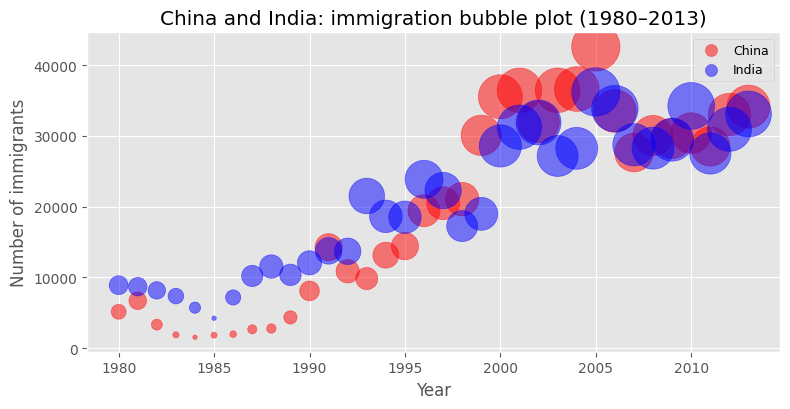

In [36]:
ax = df_can_t.plot(kind='scatter', x='Year', y='China',
    s=norm_china * 1200 + 10, alpha=0.5, color='red', label='China')
df_can_t.plot(kind='scatter', x='Year', y='India', ax=ax,
    s=norm_india * 1200 + 10, alpha=0.5, color='blue', label='India')
ax.set(title='China and India: immigration bubble plot (1980–2013)',
       ylabel='Number of immigrants')
ax.legend(markerscale=0.35, fontsize=9)
plt.show()

<details><summary>Click here for a sample python solution</summary>

```python
#The correct answer is:  
    
# China
ax0 = df_can_t.plot(kind='scatter',
                        x='Year',
                        y='China',
                        figsize=(14, 8),
                        alpha=0.5,                  # transparency
                        color='green',
                        s=norm_china * 2000 + 10,  # pass in weights 
                        xlim=(1975, 2015)
                       )

# India
ax1 = df_can_t.plot(kind='scatter',
                        x='Year',
                        y='India',
                        alpha=0.5,
                        color="blue",
                        s=norm_india * 2000 + 10,
                        ax = ax0
                       )

ax0.set_ylabel('Number of Immigrants')
ax0.set_title('Immigration from China and India from 1980 - 2013')
ax0.legend(['China', 'India'], loc='upper left', fontsize='x-large')


```

</details>


### Thank you for completing this lab!

## Author

<a href="https://www.linkedin.com/in/aklson/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01">Alex Aklson</a>

### Other Contributors

[Jay Rajasekharan](https://www.linkedin.com/in/jayrajasekharan?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01),
[Ehsan M. Kermani](https://www.linkedin.com/in/ehsanmkermani?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01),
[Slobodan Markovic](https://www.linkedin.com/in/slobodan-markovic?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01),
[Weiqing Wang](https://www.linkedin.com/in/weiqing-wang-641640133?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01),
[Pooja]().

## <h3 align="center"> © IBM Corporation 2020. All rights reserved. <h3/>

``` toggle ## Change Log
```

``` toggle| Date (YYYY-MM-DD) | Version | Changed By   | Change Description                 |
```
``` toggle| ----------------- | ------- | ------------ | ---------------------------------- |
```
``` toggle| 2023-06-11        | 2.7     | Pooja        | Updated the file to work with clean data       |
```
``` toggle| 2021-05-29        | 2.6     | Weiqing Wang | Fixed typos and code spells.       |
```
``` toggle| 2021-01-20        | 2.5     | LakshmiHolla | Changed TOC markdown section       |
```
``` toggle| 2021-01-05        | 2.4     | LakshmiHolla | Changed markdown for outliers      |
```
``` toggle| 2020-11-12        | 2.3     | LakshmiHolla | Added example code for outliers    |
```
``` toggle| 2020-11-03        | 2.2     | LakshmiHolla | Changed URL of excel file          |
```
``` toggle| 2020-09-29        | 2.1     | LakshmiHolla | Made fix to a boxplot label        |
```
``` toggle| 2020-08-27        | 2.0     | Lavanya      | Moved lab to course repo in GitLab |
```


